# Customer Segmentation using K-Means

Grouping 99,457 retail customers into 5 segments using age, quantity and total spend, to find who the big spenders are and how to target each group.

In [1]:
import pandas as pd

df = pd.read_csv("/kaggle/input/datasets/dataceo/sales-and-customer-data/sales_data.csv")
df_c = pd.read_csv("/kaggle/input/datasets/dataceo/sales-and-customer-data/customer_data.csv")

In [4]:
print(len(df), len(df_c))
print(df.head())
print(df_c.head())

99457 99457
  invoice_no customer_id  category  quantity    price invoice_date  \
0    I138884     C241288  Clothing         5  1500.40   05-08-2022   
1    I317333     C111565     Shoes         3  1800.51   12-12-2021   
2    I127801     C266599  Clothing         1   300.08   09-11-2021   
3    I173702     C988172     Shoes         5  3000.85   16-05-2021   
4    I337046     C189076     Books         4    60.60   24-10-2021   

    shopping_mall  
0          Kanyon  
1  Forum Istanbul  
2       Metrocity  
3    Metropol AVM  
4          Kanyon  
  customer_id  gender   age payment_method
0     C241288  Female  28.0    Credit Card
1     C111565    Male  21.0     Debit Card
2     C266599    Male  20.0           Cash
3     C988172  Female  66.0    Credit Card
4     C189076  Female  53.0           Cash


## Step 1. Merge the data

In [6]:
df = df.merge(df_c, on='customer_id')

## Step 2. Create total amount

In [7]:
df['total'] = df['quantity'] * df['price']
df[['quantity','price','total']].head()

,quantity,price,total
0,5,1500.40,7502.00
1,3,1800.51,5401.53
2,1,300.08,300.08
3,5,3000.85,15004.25
4,4,60.60,242.40


## Step 3: Data cleaning

In [8]:
df.info()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   invoice_no      99457 non-null  object 
 1   customer_id     99457 non-null  object 
 2   category        99457 non-null  object 
 3   quantity        99457 non-null  int64  
 4   price           99457 non-null  float64
 5   invoice_date    99457 non-null  object 
 6   shopping_mall   99457 non-null  object 
 7   gender          99457 non-null  object 
 8   age             99338 non-null  float64
 9   payment_method  99457 non-null  object 
 10  total           99457 non-null  float64
dtypes: float64(3), int64(1), object(7)
memory usage: 8.3+ MB


np.int64(0)

In [9]:
df['invoice_date'] = pd.to_datetime(df['invoice_date'], dayfirst=True)
df['invoice_date'].head()

0   2022-08-05
1   2021-12-12
2   2021-11-09
3   2021-05-16
4   2021-10-24
Name: invoice_date, dtype: datetime64[ns]

### Fixing Missing value in age

In [10]:
print("Total missing age:",df['age'].isnull().sum())

Total missing age: 119


In [11]:
df['age'] = df['age'].fillna(df['age'].median())
df['invoice_date'] = pd.to_datetime(df['invoice_date'], dayfirst=True)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99457 entries, 0 to 99456
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   invoice_no      99457 non-null  object        
 1   customer_id     99457 non-null  object        
 2   category        99457 non-null  object        
 3   quantity        99457 non-null  int64         
 4   price           99457 non-null  float64       
 5   invoice_date    99457 non-null  datetime64[ns]
 6   shopping_mall   99457 non-null  object        
 7   gender          99457 non-null  object        
 8   age             99457 non-null  float64       
 9   payment_method  99457 non-null  object        
 10  total           99457 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(6)
memory usage: 8.3+ MB


## Step 4: EDA (Exploratory Data Analysis)

In [13]:
df[['age','quantity','price','total']].describe()

,age,quantity,price,total
count,99457.000000,99457.000000,99457.000000,99457.000000
mean,43.425350,3.003429,689.256321,2528.789268
std,14.980437,1.413025,941.184567,4222.475781
min,18.000000,1.000000,5.230000,5.230000
25%,30.000000,2.000000,45.450000,136.350000
50%,43.000000,3.000000,203.300000,600.170000
75%,56.000000,4.000000,1200.320000,2700.720000
max,69.000000,5.000000,5250.000000,26250.000000


In [14]:
df['category'].value_counts()

category
Clothing           34487
Cosmetics          15097
Food & Beverage    14776
Toys               10087
Shoes              10034
Souvenir            4999
Technology          4996
Books               4981
Name: count, dtype: int64

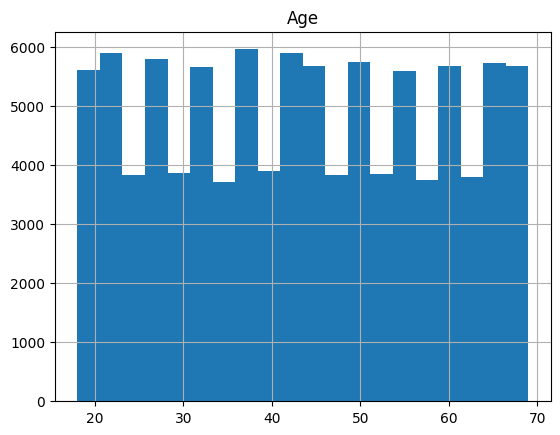

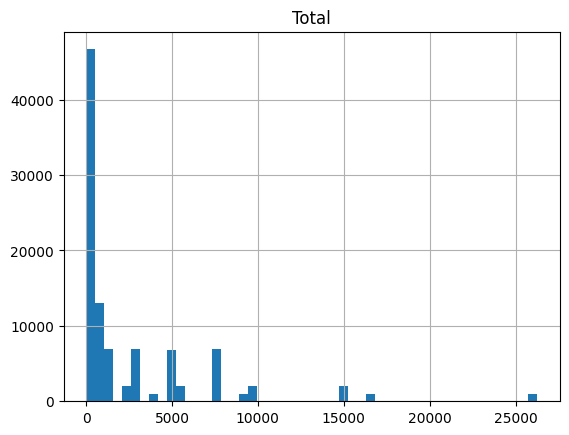

category
Technology         11581.735388
Shoes               6632.793649
Clothing            3305.500364
Cosmetics            449.947864
Toys                 394.609521
Books                167.547260
Souvenir             127.190368
Food & Beverage       57.494251
Name: total, dtype: float64

In [15]:
import matplotlib.pyplot as plt

df['age'].hist(bins=20)
plt.title("Age")
plt.show()

df['total'].hist(bins=50)
plt.title("Total")
plt.show()

df.groupby('category')['total'].mean().sort_values(ascending=False)

## Step 5. Select features and scale

In [16]:
from sklearn.preprocessing import StandardScaler

X = df[['age','quantity','total']]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-1.02970476e+00  1.41298366e+00  1.17780089e+00]
 [-1.49698320e+00 -2.42644985e-03  6.80348526e-01]
 [-1.56373727e+00 -1.41783656e+00 -5.27823151e-01]
 [ 1.50694963e+00  1.41298366e+00  2.95455181e+00]
 [ 6.39146812e-01  7.05278603e-01 -5.41483452e-01]]


## Step 6. Find best K

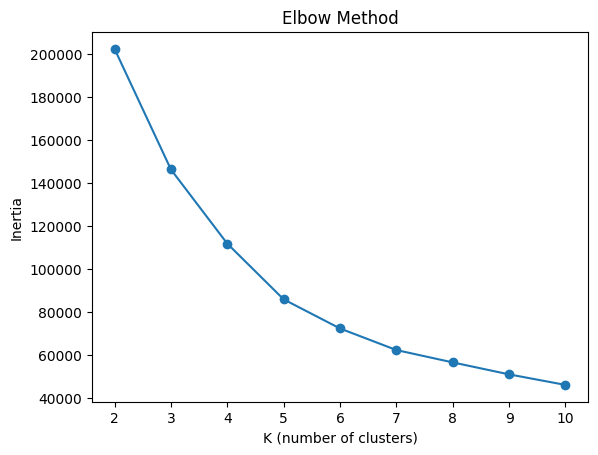

In [17]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
for k in range(2,11):
    km = KMeans(n_clusters=k, random_state=42,n_init=10)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.plot(range(2,11),inertia,marker='o')
plt.xlabel("K (number of clusters)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

## Step 7. Train K-Means

In [18]:
Kmeans = KMeans(n_clusters=5, random_state=42,n_init=10)
df['cluster'] = Kmeans.fit_predict(X_scaled)

df['cluster'].value_counts().sort_index()

cluster
0    20221
1    20657
2    27054
3    27510
4     4015
Name: count, dtype: int64

## Step 8. Understand each cluster

In [19]:
df.groupby('cluster')[['age','quantity','total']].mean().round(1)

,age,quantity,total
cluster,,,
0,55.7,4.4,3698.2
1,31.0,1.5,561.0
2,30.1,3.9,2606.0
3,56.8,2.0,775.5
4,43.4,4.8,18255.7


In [20]:
df.groupby('cluster')['category'].agg(lambda x: x.value_counts().index[0])

cluster
0    Clothing
1    Clothing
2    Clothing
3    Clothing
4       Shoes
Name: category, dtype: object

In [23]:
df.groupby('cluster')['total'].sum()

cluster
0    74781095.08
1    11589574.91
2    70503849.26
3    21334669.75
4    73296605.25
Name: total, dtype: float64

## Step 9: Visualize

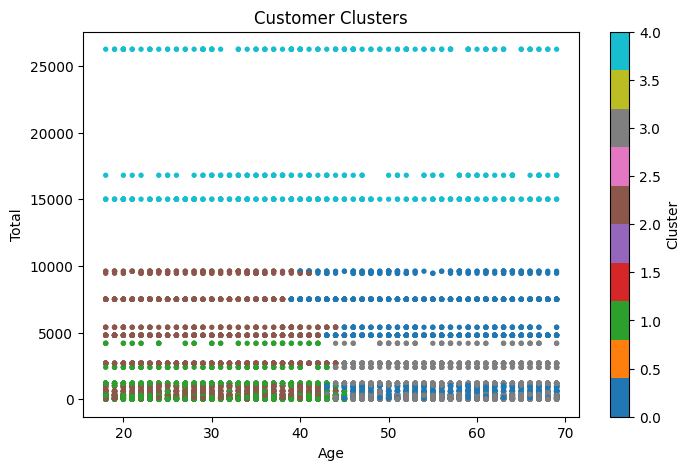

In [21]:
sample = df.sample(10000, random_state=42)

plt.figure(figsize=(8,5))
plt.scatter(sample['age'],sample['total'], c=sample['cluster'],cmap='tab10',s=8)
plt.xlabel("Age")
plt.ylabel("Total")
plt.title("Customer Clusters")
plt.colorbar(label="Cluster")
plt.show()

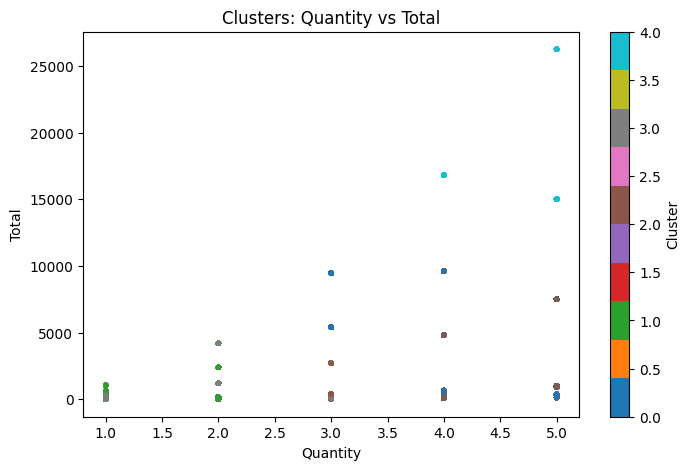

In [22]:
plt.figure(figsize=(8, 5))
plt.scatter(sample['quantity'], sample['total'], c=sample['cluster'], cmap='tab10', s=8)
plt.xlabel("Quantity")
plt.ylabel("Total")
plt.title("Clusters: Quantity vs Total")
plt.colorbar(label="Cluster")
plt.show()

## Step 10. Conclusion.

What I did: I used K-Means on 99,457 customers with age, quantity and total spend. I scaled the data and chose K = 5 using the elbow method.

What I found:

Cluster 4 (4% of customers) are premium big spenders and give about 29% of the revenue.
Cluster 0 (older, buy many items) gives about 30% of the revenue.
Cluster 2 (young, buy many items) gives about 28%.
Clusters 1 and 3 are light buyers. They are 49% of customers but only about 13% of revenue.

Business suggestions:

Give clusters 0 and 4 loyalty rewards and early access to new products, so they stay.
For cluster 2, offer bundles and member offers to keep them buying.
For clusters 1 and 3, use combo offers to increase how many items they buy.

Limitations: Each customer bought only once, so I could not use RFM. The elbow was not sharp, so K = 4 or 6 could also work. I used only three features. Next, I can add gender, payment method and category.